# Visit with Us: Tourism Package Purchase Prediction

## Business objective
Build a reproducible MLOps workflow that helps the marketing team prioritize customers who may purchase a tourism package, using the supplied customer and sales-interaction data.

> **Label limitation:** `ProdTaken` records a general package purchase. The provided data does not identify Wellness Tourism Package purchases, so this model is not evidence of Wellness-specific customer intent. It supports prioritization only and should not replace customer choice or human judgment.

This notebook validates the repository dataset, explores and prepares it, tunes approved classifiers using training-only cross-validation, evaluates the selected pipeline on the holdout set, and summarizes deployment and CI/CD readiness.

**Repository:** [Lakshman-14/ML_experiments](https://github.com/Lakshman-14/ML_experiments)  
**Streamlit Community Cloud app:** [Open the deployed app](https://mlexperiments-lakshman.streamlit.app/)  
**Dataset:** [`data/tourism.csv`](../data/tourism.csv)

## 1. Data registration and validation
The dataset is registered under the repository `data/` folder. The validation script checks the required schema and target values and reports row counts, class counts, unexpected columns, and missingness. The CSV contains an exported index column (`Unnamed: 0`); it is removed during preparation rather than used as a predictor.

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "data" / "tourism.csv").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.validate_data import validate_data

DATA_PATH = ROOT / "data" / "tourism.csv"
data = validate_data(DATA_PATH)
display(data.head())

Dataset: /Users/lakshmanraghu/Documents/Great Learning/MLOps Tourism Package Prediction/data/tourism.csv
Shape: 4,128 rows x 21 columns
Target counts:
ProdTaken
0    3331
1     797
Name: count, dtype: int64
Missing values by column:
None
Unexpected columns: ['Unnamed: 0']


,Unnamed: 0,CustomerID,ProdTaken,Age,TypeofContact,CityTier,DurationOfPitch,Occupation,Gender,NumberOfPersonVisiting,...,ProductPitched,PreferredPropertyStar,MaritalStatus,NumberOfTrips,Passport,PitchSatisfactionScore,OwnCar,NumberOfChildrenVisiting,Designation,MonthlyIncome
0,0,200000,1,41.0,Self Enquiry,3,6.0,Salaried,Female,3,...,Deluxe,3.0,Single,1.0,1,2,1,0.0,Manager,20993.0
1,1,200001,0,49.0,Company Invited,1,14.0,Salaried,Male,3,...,Deluxe,4.0,Divorced,2.0,0,3,1,2.0,Manager,20130.0
2,2,200002,1,37.0,Self Enquiry,1,8.0,Free Lancer,Male,3,...,Basic,3.0,Single,7.0,1,3,0,0.0,Executive,17090.0
3,3,200003,0,33.0,Company Invited,1,9.0,Salaried,Female,2,...,Basic,3.0,Divorced,2.0,1,5,1,1.0,Executive,17909.0
4,5,200005,0,32.0,Company Invited,1,8.0,Salaried,Male,3,...,Basic,3.0,Single,1.0,0,5,1,1.0,Executive,18068.0


## 2. Initial data exploration
The target is imbalanced, so accuracy alone would hide the minority-class performance. We will use F1 for cross-validation model selection and report precision, recall, F1, ROC-AUC, and the confusion matrix on a stratified holdout set. Missing-value handling remains inside the fitted preprocessing pipeline to avoid leakage.

Rows: 4,128; columns: 21

Data types:


,dtype
Unnamed: 0,int64
CustomerID,int64
ProdTaken,int64
Age,float64
TypeofContact,object
CityTier,int64
DurationOfPitch,float64
Occupation,object
Gender,object
NumberOfPersonVisiting,int64



Missing values:


,missing
Unnamed: 0,0
ProductPitched,0
Designation,0
NumberOfChildrenVisiting,0
OwnCar,0
PitchSatisfactionScore,0
Passport,0
NumberOfTrips,0
MaritalStatus,0
PreferredPropertyStar,0



Target distribution:


,customers,share
ProdTaken,,
No purchase,3331,0.806928
Purchase,797,0.193072


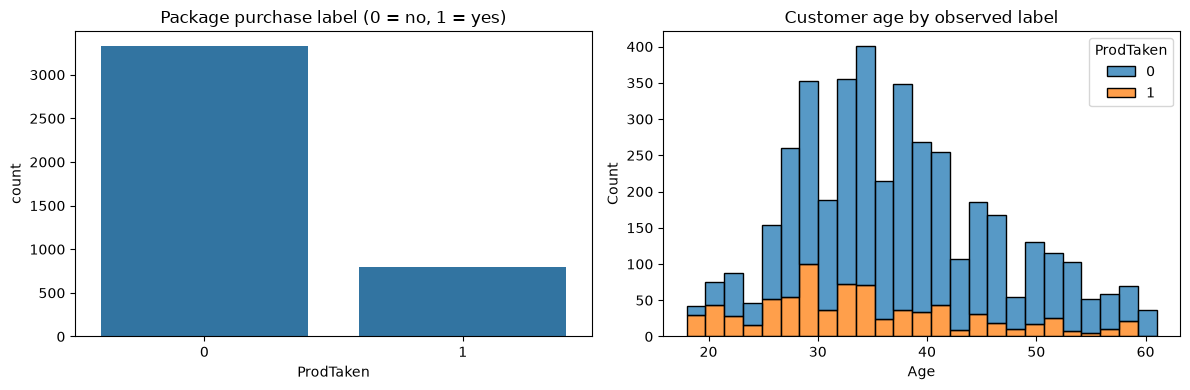

In [2]:
print(f"Rows: {len(data):,}; columns: {data.shape[1]}")
print("\nData types:")
display(data.dtypes.rename("dtype").to_frame())
print("\nMissing values:")
display(data.isna().sum().sort_values(ascending=False).head(10).rename("missing").to_frame())
print("\nTarget distribution:")
target_summary = data["ProdTaken"].value_counts().sort_index().rename(index={0: "No purchase", 1: "Purchase"})
display(pd.concat([target_summary.rename("customers"), (target_summary / len(data)).rename("share")], axis=1))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=data, x="ProdTaken", ax=axes[0])
axes[0].set_title("Package purchase label (0 = no, 1 = yes)")
sns.histplot(data=data, x="Age", hue="ProdTaken", bins=25, multiple="stack", ax=axes[1])
axes[1].set_title("Customer age by observed label")
plt.tight_layout()
plt.show()

## 3. Data preparation
A fixed random seed and stratified 80/20 split preserve the observed class balance. The exported index and the identifier `CustomerID` are excluded; the target is retained only as the label. Training and test data are saved separately for local use and are transferred between GitHub Actions jobs as a workflow artifact.

In [3]:
from src.prepare_data import prepare_data

SPLIT_DIR = ROOT / "artifacts" / "splits"
train_path, test_path = prepare_data(DATA_PATH, SPLIT_DIR)
train_data = pd.read_csv(train_path)
test_data = pd.read_csv(test_path)
print(f"Train rows: {len(train_data):,}; test rows: {len(test_data):,}")
print("Train target proportions:")
display(train_data["ProdTaken"].value_counts(normalize=True).sort_index().rename("share").to_frame())

Dataset: /Users/lakshmanraghu/Documents/Great Learning/MLOps Tourism Package Prediction/data/tourism.csv
Shape: 4,128 rows x 21 columns
Target counts:
ProdTaken
0    3331
1     797
Name: count, dtype: int64
Missing values by column:
None
Unexpected columns: ['Unnamed: 0']
Training split: /Users/lakshmanraghu/Documents/Great Learning/MLOps Tourism Package Prediction/artifacts/splits/train.csv (3,302 rows)
Testing split: /Users/lakshmanraghu/Documents/Great Learning/MLOps Tourism Package Prediction/artifacts/splits/test.csv (826 rows)
Training class balance:
ProdTaken
0    0.806784
1    0.193216
Name: proportion, dtype: float64
Train rows: 3,302; test rows: 826
Train target proportions:


,share
ProdTaken,
0,0.806784
1,0.193216


## 4. Model building and experimentation tracking
The training script compares Decision Tree, Random Forest, and Gradient Boosting pipelines. Numeric missing values are imputed and scaled; categorical missing values are imputed and one-hot encoded with unseen categories ignored. Grid search uses stratified cross-validation and training-only F1 to select the model. Every candidate's parameters and CV results are persisted in `model/cv_results.csv`; the best complete preprocessing/model pipeline is serialized for deployment.

In [4]:
from src.train_model import train_model

MODEL_DIR = ROOT / "model"
metrics = train_model(train_path, test_path, MODEL_DIR)
cv_results = pd.read_csv(MODEL_DIR / "cv_results.csv")
print(f"Candidate configurations logged: {len(cv_results)}")
display(cv_results.sort_values("rank_test_score")[
    ["rank_test_score", "mean_test_score", "std_test_score", "params"]
].head(10))

{
  "selection_metric": "mean cross-validated F1",
  "best_cv_f1": 0.641140438451728,
  "best_parameters": {
    "model": "DecisionTreeClassifier",
    "model__max_depth": null,
    "model__min_samples_leaf": 1
  },
  "test_metrics": {
    "accuracy": 0.8934624697336562,
    "precision": 0.7204968944099379,
    "recall": 0.7295597484276729,
    "f1": 0.725,
    "roc_auc": 0.831046740780553,
    "confusion_matrix_labels_0_1": [
      [
        622,
        45
      ],
      [
        43,
        116
      ]
    ]
  },
  "test_rows": 826
}
Tuning combinations logged: 18
Saved selected pipeline: /Users/lakshmanraghu/Documents/Great Learning/MLOps Tourism Package Prediction/model/best_model.joblib
Candidate configurations logged: 18


,rank_test_score,mean_test_score,std_test_score,params
4,1,0.641140,0.012773,"{""model"": ""DecisionTreeClassifier"", ""model__ma..."
8,2,0.637950,0.048457,"{""model"": ""RandomForestClassifier"", ""model__ma..."
6,3,0.588265,0.041591,"{""model"": ""RandomForestClassifier"", ""model__ma..."
2,4,0.569172,0.022509,"{""model"": ""DecisionTreeClassifier"", ""model__ma..."
5,5,0.549728,0.028773,"{""model"": ""DecisionTreeClassifier"", ""model__ma..."
17,6,0.542198,0.022318,"{""model"": ""GradientBoostingClassifier"", ""model..."
3,7,0.538546,0.042464,"{""model"": ""DecisionTreeClassifier"", ""model__ma..."
16,8,0.512889,0.031347,"{""model"": ""GradientBoostingClassifier"", ""model..."
13,9,0.486048,0.026179,"{""model"": ""GradientBoostingClassifier"", ""model..."
9,10,0.469688,0.039358,"{""model"": ""RandomForestClassifier"", ""model__ma..."


## 5. Held-out evaluation
These test metrics are reported after model selection and are not used to tune candidate models. The default classifier decision threshold is 0.5; a production campaign should choose its operating threshold using an explicit outreach-capacity and error-cost analysis on validation data.

{
  "selection_metric": "mean cross-validated F1",
  "best_cv_f1": 0.641140438451728,
  "best_parameters": {
    "model": "DecisionTreeClassifier",
    "model__max_depth": null,
    "model__min_samples_leaf": 1
  },
  "test_metrics": {
    "accuracy": 0.8934624697336562,
    "precision": 0.7204968944099379,
    "recall": 0.7295597484276729,
    "f1": 0.725,
    "roc_auc": 0.831046740780553,
    "confusion_matrix_labels_0_1": [
      [
        622,
        45
      ],
      [
        43,
        116
      ]
    ]
  },
  "test_rows": 826
}


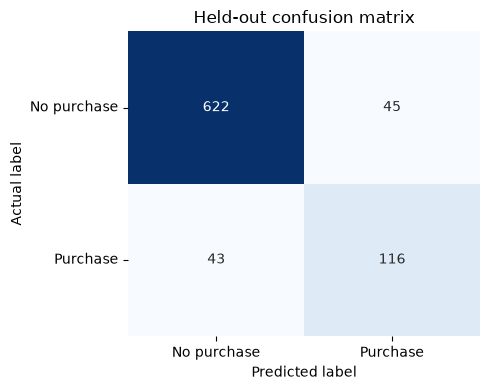

At threshold 0.5, the holdout F1 is 0.725, precision is 0.720, and recall is 0.730. Use precision and recall together when considering outreach capacity and missed buyers.


In [5]:
from IPython.display import Markdown, display

print(json.dumps(metrics, indent=2))
matrix = metrics["test_metrics"]["confusion_matrix_labels_0_1"]
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
ax.set(xlabel="Predicted label", ylabel="Actual label", title="Held-out confusion matrix")
ax.set_xticklabels(["No purchase", "Purchase"])
ax.set_yticklabels(["No purchase", "Purchase"], rotation=0)
plt.tight_layout()
plt.show()

best = metrics["test_metrics"]
print(
    f"At threshold 0.5, the holdout F1 is {best['f1']:.3f}, "
    f"precision is {best['precision']:.3f}, and recall is {best['recall']:.3f}. "
    "Use precision and recall together when considering outreach capacity and missed buyers."
)

## 6. Deployment, CI/CD, and evidence
- `app.py` loads the committed fitted pipeline and creates an input dataframe with the feature names recorded during training.
- `requirements.txt` declares deployment dependencies for Streamlit Community Cloud.
- `.github/workflows/pipeline.yml` validates data, passes train/test split artifacts between jobs, trains and tests the pipeline, then updates model outputs on `master` when they change. Repository Actions write permissions must be enabled for the model commit step.
- GitHub repository URL: [Lakshman-14/ML_experiments](https://github.com/Lakshman-14/ML_experiments)
- Streamlit Community Cloud URL: [https://mlexperiments-lakshman.streamlit.app/](https://mlexperiments-lakshman.streamlit.app/)
- The public app was opened, a sample prediction was submitted successfully, and the result was visually verified. Screenshot: [`artifacts/streamlit-app.png`](../artifacts/streamlit-app.png).
- Repository structure screenshot: [`artifacts/github-repository.png`](../artifacts/github-repository.png).
- Successful GitHub Actions workflow screenshot: [`artifacts/github-actions-success.png`](../artifacts/github-actions-success.png); [open the workflow run](https://github.com/Lakshman-14/ML_experiments/actions/runs/40202166576).
- **Before-contact limitation:** the available fields include pitch duration, pitch satisfaction, product pitched, and follow-up count. These are only known after a sales interaction, so this current model is not suitable for pre-contact targeting. For that use, train and evaluate a separate version using only features known before outreach.

## 7. Business insights and next steps
The data contains a majority of non-purchasers, so campaign decisions should consider the false-positive and false-negative counts, not accuracy alone. Use predicted propensity to prioritize a measured pilot, evaluate conversion and cost per acquisition, and monitor performance and drift over time. Before targeting a Wellness offering, collect a package-specific outcome label and validate the model on that outcome. Review fairness, consent, and contact policies before operational use.

### Rubric status
Data registration, reproducible preparation, tuned model tracking/evaluation, Streamlit app code, GitHub Actions workflow, and public Streamlit Community Cloud deployment are complete. The repository is [Lakshman-14/ML_experiments](https://github.com/Lakshman-14/ML_experiments), and the app is available at [mlexperiments-lakshman.streamlit.app](https://mlexperiments-lakshman.streamlit.app/).